# Sprawozdanie — Zajęcia 1

## 1. Instalacja bibliotek

In [2]:
#!pip -q install librosa soundfile matplotlib numpy scipy

## 2. Import i parametry

In [3]:
import warnings
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
from scipy.signal import lfilter

warnings.filterwarnings("ignore", category=FutureWarning)

SR = 16000
N_FFT = 512   
HOP_LENGTH = 160
N_MELS = 64      
N_MFCC = 13     

plt.rcParams["figure.dpi"] = 100

## 3. Wczytanie trzech nagrań

In [4]:
NAGRANIA = {
    "Samogłoska": r"C:\Users\macze\OneDrive\Pulpit\sprawozdanie 1\aaaa.wav",
    "Wyraz":      r"C:\Users\macze\OneDrive\Pulpit\sprawozdanie 1\sprawozdanie.wav",
    "Zdanie":     r"C:\Users\macze\OneDrive\Pulpit\sprawozdanie 1\dzisiaj_robie_sprawozdanie.wav",
}

In [5]:
import os

def wczytaj_audio(sciezka):
    if not os.path.exists(sciezka):
        raise FileNotFoundError(f"Nie znaleziono pliku: {sciezka}")
    y, sr = librosa.load(sciezka, sr=SR, mono=True)
    y, _ = librosa.effects.trim(y, top_db=35)
    y = y / (np.max(np.abs(y)) + 1e-9) * 0.9
    return y.astype(np.float32)

AUDIO = {}
for nazwa, sciezka in NAGRANIA.items():
    y = wczytaj_audio(sciezka)
    AUDIO[nazwa] = y
    print(f"{nazwa:11s} | {len(y):6d} próbek | {len(y)/SR:5.2f} s | {SR} Hz | plik: {sciezka}")

Samogłoska  |   7680 próbek |  0.48 s | 16000 Hz | plik: C:\Users\macze\OneDrive\Pulpit\sprawozdanie 1\aaaa.wav
Wyraz       |  15360 próbek |  0.96 s | 16000 Hz | plik: C:\Users\macze\OneDrive\Pulpit\sprawozdanie 1\sprawozdanie.wav
Zdanie      |  28160 próbek |  1.76 s | 16000 Hz | plik: C:\Users\macze\OneDrive\Pulpit\sprawozdanie 1\dzisiaj_robie_sprawozdanie.wav


## 4. Odsłuch

In [6]:
from IPython.display import Audio, display
for nazwa, y in AUDIO.items():
    print(nazwa)
    display(Audio(y, rate=SR))

Samogłoska


Wyraz


Zdanie


## 5. Reprezentacje: przebieg, log-mel, MFCC

In [7]:
def log_mel(y, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels)
    return librosa.power_to_db(S, ref=np.max)

def mfcc(y, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mfcc=N_MFCC, n_mels=N_MELS):
    return librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc, n_fft=n_fft,
                                hop_length=hop_length, n_mels=n_mels)

REPR = {}
for nazwa, y in AUDIO.items():
    REPR[nazwa] = {"log_mel": log_mel(y), "mfcc": mfcc(y)}
    print(f"{nazwa:11s} log-mel: {REPR[nazwa]['log_mel'].shape}   MFCC: {REPR[nazwa]['mfcc'].shape}   (cechy × ramki)")

Samogłoska  log-mel: (64, 49)   MFCC: (13, 49)   (cechy × ramki)
Wyraz       log-mel: (64, 97)   MFCC: (13, 97)   (cechy × ramki)
Zdanie      log-mel: (64, 177)   MFCC: (13, 177)   (cechy × ramki)


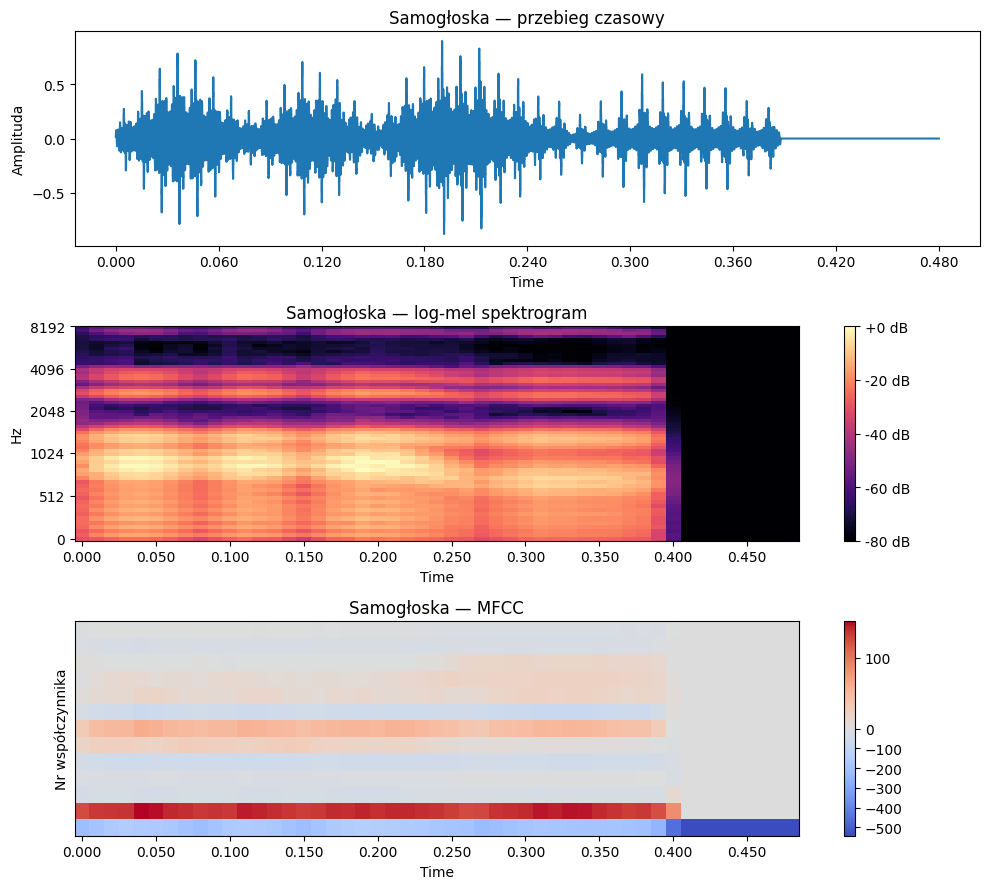

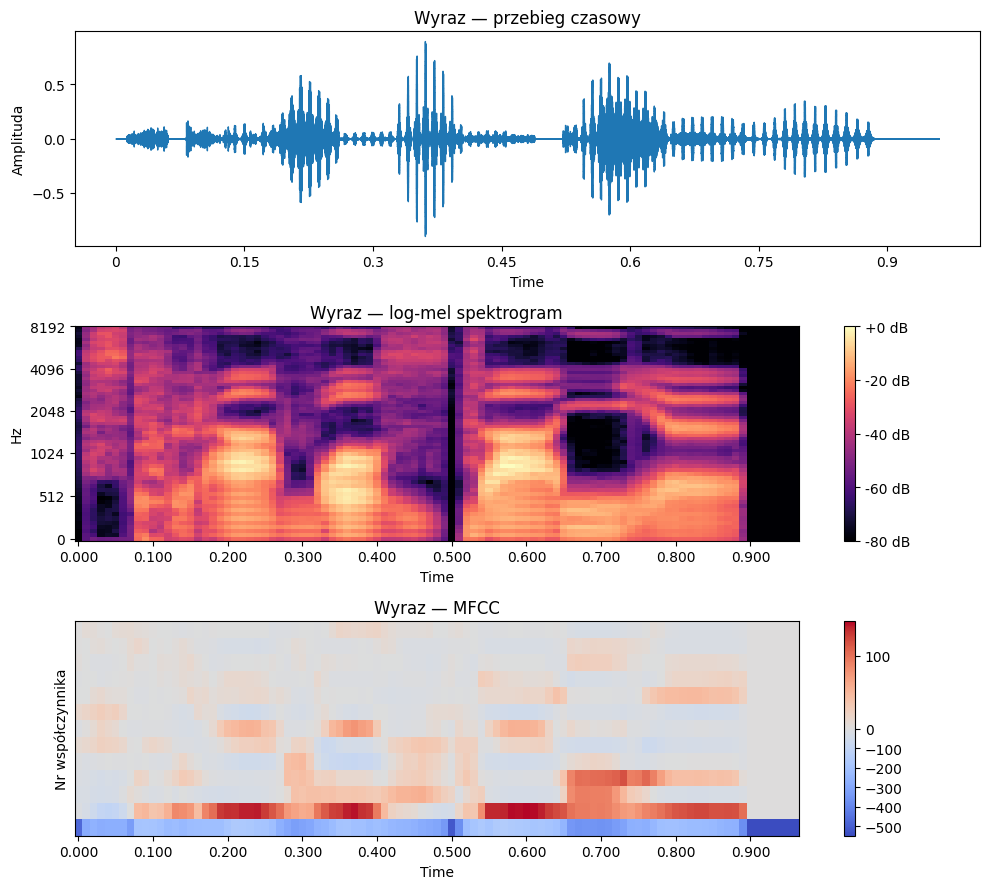

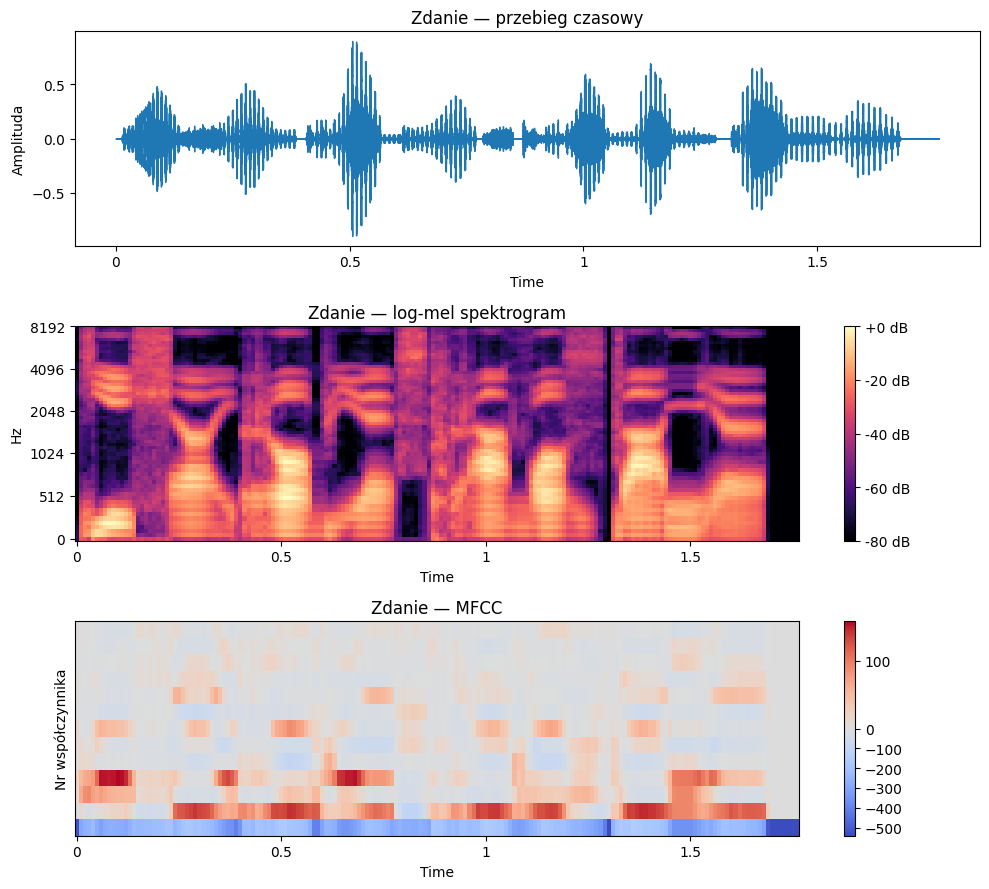

In [8]:
for nazwa, y in AUDIO.items():
    S_db, M = REPR[nazwa]["log_mel"], REPR[nazwa]["mfcc"]
    fig, ax = plt.subplots(3, 1, figsize=(10, 9))

    librosa.display.waveshow(y, sr=SR, ax=ax[0])
    ax[0].set_title(f"{nazwa} — przebieg czasowy")
    ax[0].set_ylabel("Amplituda")

    img1 = librosa.display.specshow(S_db, sr=SR, hop_length=HOP_LENGTH, x_axis="time", y_axis="mel", ax=ax[1])
    ax[1].set_title(f"{nazwa} — log-mel spektrogram")
    fig.colorbar(img1, ax=ax[1], format="%+2.0f dB")

    img2 = librosa.display.specshow(M, sr=SR, hop_length=HOP_LENGTH, x_axis="time", ax=ax[2])
    ax[2].set_title(f"{nazwa} — MFCC")
    ax[2].set_ylabel("Nr współczynnika")
    fig.colorbar(img2, ax=ax[2])

    plt.tight_layout()
    plt.show()

### 5.1 Porównanie liczbowe nagrań

- **czas trwania** i **liczba ramek**,
- **udział ramek ciszy** 
- **średni centroid widmowy**
- **zmienność w czasie** 
- **odchylenie standardowe MFCC w czasie**

In [9]:
wiersze = []
for nazwa, y in AUDIO.items():
    S_db, M = REPR[nazwa]["log_mel"], REPR[nazwa]["mfcc"]
    rms = librosa.feature.rms(y=y, frame_length=N_FFT, hop_length=HOP_LENGTH)[0]
    cisza = np.mean(rms < 0.1 * rms.max()) * 100
    centroid = librosa.feature.spectral_centroid(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH)[0].mean()
    zmiennosc = np.mean(np.abs(np.diff(S_db, axis=1)))
    std_mfcc = M[1:].std(axis=1).mean()
    wiersze.append((nazwa, len(y) / SR, S_db.shape[1], cisza, centroid, zmiennosc, std_mfcc))

naglowek = f"{'Nagranie':11s} {'t [s]':>6s} {'ramki':>6s} {'cisza [%]':>10s} {'centroid [Hz]':>14s} {'zmienność [dB]':>15s} {'std MFCC':>9s}"
print(naglowek)
print("-" * len(naglowek))
for w in wiersze:
    print(f"{w[0]:11s} {w[1]:6.2f} {w[2]:6d} {w[3]:10.1f} {w[4]:14.0f} {w[5]:15.2f} {w[6]:9.2f}")

Nagranie     t [s]  ramki  cisza [%]  centroid [Hz]  zmienność [dB]  std MFCC
-----------------------------------------------------------------------------
Samogłoska    0.48     49       18.4           1146            2.60     14.88
Wyraz         0.96     97       21.6           1866            4.78     25.33
Zdanie        1.76    177       26.6           1829            4.83     26.58


## 6. Wpływ `n_fft` i `hop_length`

- długość okna: `n_fft / SR` — np. 256 → 16 ms, 512 → 32 ms, 1024 → 64 ms,
- rozdzielczość częstotliwościowa: `SR / n_fft` — np. 256 → 62,5 Hz, 512 → 31,25 Hz, 1024 → 15,6 Hz,
- krok czasowy: `hop_length / SR` — np. 80 → 5 ms, 160 → 10 ms, 320 → 20 ms,
- liczba ramek ≈ `1 + len(y) / hop_length`.

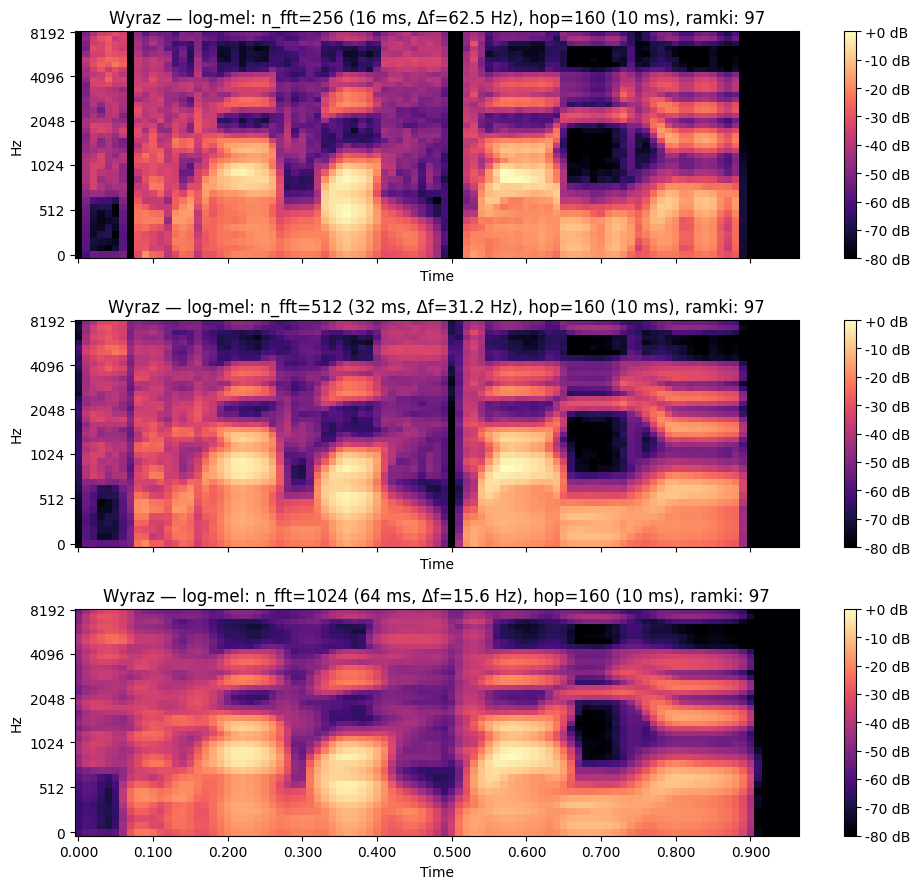

In [ ]:
BADANE = "Wyraz"
yb = AUDIO[BADANE]

def opis(n_fft, hop):
    return (f"n_fft={n_fft} ({n_fft/SR*1000:.0f} ms, Δf={SR/n_fft:.1f} Hz), "
            f"hop={hop} ({hop/SR*1000:.0f} ms)")
NFFTS = [256, 512, 1024]
fig, axes = plt.subplots(len(NFFTS), 1, figsize=(10, 9), sharex=True)
for ax, nf in zip(axes, NFFTS):
    S = log_mel(yb, n_fft=nf, hop_length=160, n_mels=40)
    img = librosa.display.specshow(S, sr=SR, hop_length=160, x_axis="time", y_axis="mel", ax=ax)
    ax.set_title(f"{BADANE} — log-mel: {opis(nf, 160)}, ramki: {S.shape[1]}")
    fig.colorbar(img, ax=ax, format="%+2.0f dB")
plt.tight_layout(); plt.show()

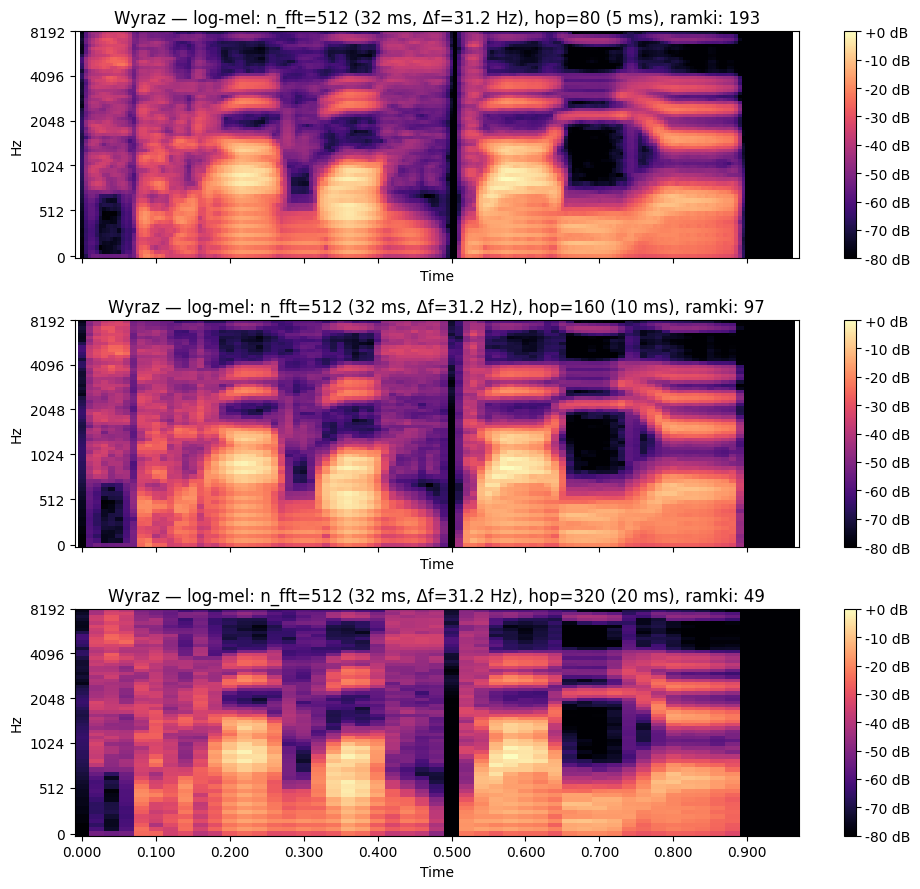

In [ ]:
HOPS = [80, 160, 320]
fig, axes = plt.subplots(len(HOPS), 1, figsize=(10, 9), sharex=True)
for ax, hp in zip(axes, HOPS):
    S = log_mel(yb, n_fft=512, hop_length=hp)
    img = librosa.display.specshow(S, sr=SR, hop_length=hp, x_axis="time", y_axis="mel", ax=ax)
    ax.set_title(f"{BADANE} — log-mel: {opis(512, hp)}, ramki: {S.shape[1]}")
    fig.colorbar(img, ax=ax, format="%+2.0f dB")
plt.tight_layout(); plt.show()

### 6.1 Widmo liniowe samogłoski 

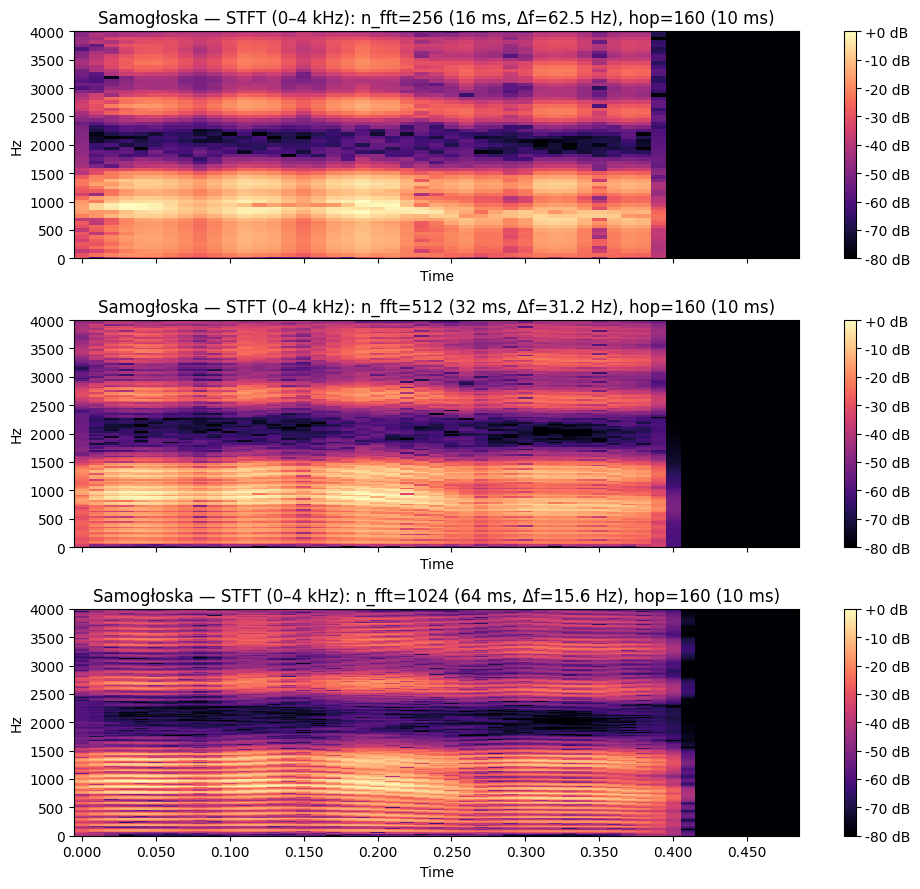

In [12]:
yv = AUDIO["Samogłoska"]
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for ax, nf in zip(axes, [256, 512, 1024]):
    D = librosa.amplitude_to_db(np.abs(librosa.stft(yv, n_fft=nf, hop_length=160)), ref=np.max)
    img = librosa.display.specshow(D, sr=SR, hop_length=160, x_axis="time", y_axis="hz", ax=ax)
    ax.set_ylim(0, 4000)
    ax.set_title(f"Samogłoska — STFT (0–4 kHz): {opis(nf, 160)}")
    fig.colorbar(img, ax=ax, format="%+2.0f dB")
plt.tight_layout(); plt.show()

### 6.2 Zestawienie rozmiarów reprezentacji

In [13]:
print(f"{'n_fft':>6s} {'hop':>5s} {'okno [ms]':>10s} {'krok [ms]':>10s} {'Δf [Hz]':>8s} {'ramki':>6s} {'kształt log-mel':>16s}")
for nf, hp in [(256, 160), (512, 160), (1024, 160), (512, 80), (512, 320)]:
    S = log_mel(yb, n_fft=nf, hop_length=hp, n_mels=40 if nf == 256 else N_MELS)
    print(f"{nf:6d} {hp:5d} {nf/SR*1000:10.0f} {hp/SR*1000:10.0f} {SR/nf:8.1f} {S.shape[1]:6d} {str(S.shape):>16s}")

 n_fft   hop  okno [ms]  krok [ms]  Δf [Hz]  ramki  kształt log-mel
   256   160         16         10     62.5     97         (40, 97)
   512   160         32         10     31.2     97         (64, 97)
  1024   160         64         10     15.6     97         (64, 97)
   512    80         32          5     31.2    193        (64, 193)
   512   320         32         20     31.2     49         (64, 49)
